In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv(r"C:\Users\Siddarood\Data Science 2\DS Morning 9th Feb 2026\DS Morning 9th Feb 2026\driver-data.csv")

In [3]:
df.shape

(4000, 3)

In [4]:
df.head()

,id,mean_dist_day,mean_over_speed_perc
0,3423311935,71.24,28
1,3423313212,52.53,25
2,3423313724,64.54,27
3,3423311373,55.69,22
4,3423310999,54.58,25


This data contains drivers data and build a cluster model based on distance & speed.
The data containg avg distance and avg over speed of the driver
here we need to create cluster who are belonging to 1.driver going to long distance and high speed
2. driver going to low distance high speed
3. driver going low distance high speed
4. driver going to low distance low speed

In [5]:
### Here the id is not important as per now we are dropping that
features = df.drop(columns=['id'])

In [6]:
features.head()

,mean_dist_day,mean_over_speed_perc
0,71.24,28
1,52.53,25
2,64.54,27
3,55.69,22
4,54.58,25


In [13]:
features.describe()

,mean_dist_day,mean_over_speed_perc
count,4000.000000,4000.000000
mean,76.041522,10.721000
std,53.469563,13.708543
min,15.520000,0.000000
25%,45.247500,4.000000
50%,53.330000,6.000000
75%,65.632500,9.000000
max,244.790000,100.000000


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum()

id                      0
mean_dist_day           0
mean_over_speed_perc    0
dtype: int64

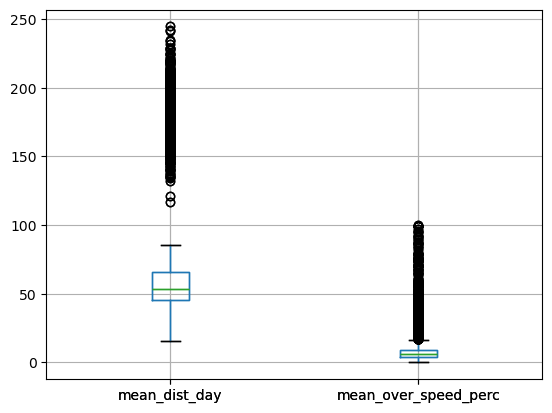

In [12]:
features.boxplot()
plt.show()

In [14]:
std = StandardScaler()
features1= pd.DataFrame(std.fit_transform(features),columns=features.columns)

In [15]:
features1.head()

,mean_dist_day,mean_over_speed_perc
0,-0.089810,1.260613
1,-0.439773,1.041744
2,-0.215131,1.187656
3,-0.380666,0.822875
4,-0.401428,1.041744


In [17]:
kmeans = KMeans(n_clusters=3,random_state=50)
cluster = kmeans.fit(features1)

In [18]:
np.unique(cluster.labels_)

array([0, 1, 2], dtype=int32)

In [19]:
df['cluster'] = cluster.labels_

In [20]:
df.head()

,id,mean_dist_day,mean_over_speed_perc,cluster
0,3423311935,71.24,28,1
1,3423313212,52.53,25,0
2,3423313724,64.54,27,1
3,3423311373,55.69,22,0
4,3423310999,54.58,25,0


In [24]:
# the no of people belonging to group 1
df[df.cluster==0].shape

(2903, 4)

In [25]:
df[df.cluster==1].shape

(403, 4)

In [26]:
df[df.cluster==2].shape

(694, 4)

In [32]:
features1['cluster']=cluster.labels_

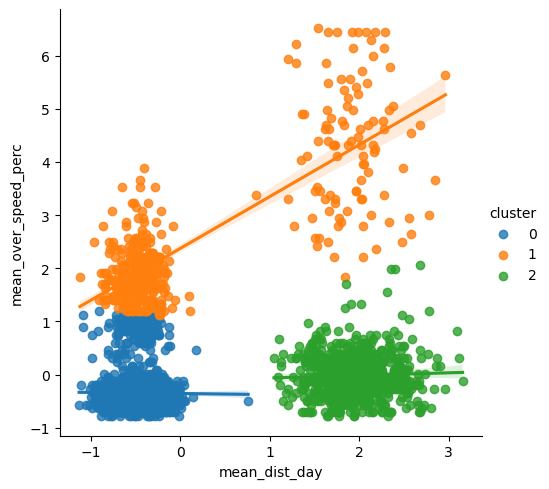

In [33]:
# This is known as linear modle plot.
sns.lmplot(data=features1,x='mean_dist_day',y='mean_over_speed_perc',hue='cluster')
plt.show()

In [34]:
cluster.cluster_centers_

array([[-0.48707569, -0.34543211],
       [ 0.14575993,  2.51698215],
       [ 1.95279463, -0.01664897]])

In [36]:
# To get the out put we passed our oiriginal i.e is feature,
# cluster is our predicted
silhouette_score(features1,cluster.labels_)

0.8046268444611562

In [37]:
kmeans.inertia_

1756.544582131427

In [38]:
!pip install yellowbrick

In [39]:
from yellowbrick.cluster import KElbowVisualizer

In [47]:
elbow_visualizer = KElbowVisualizer(estimator=KMeans(),k=(2,11),metric='distortion')
elbow_visualizer.fit(features1)

,estimator,KMeans(n_clusters=10)
,ax,<Axes: >
,k,"(2, ...)"
,metric,'distortion'
,distance_metric,'euclidean'
,timings,True
,locate_elbow,True
,n_clusters,10
,init,'k-means++'
,n_init,'auto'
,max_iter,300


* To plot elbow curve we have two parameter 1.Inertia, 2.silhoute score 
* If Inertia=4 and silhoutte score=5 chose the bigger number

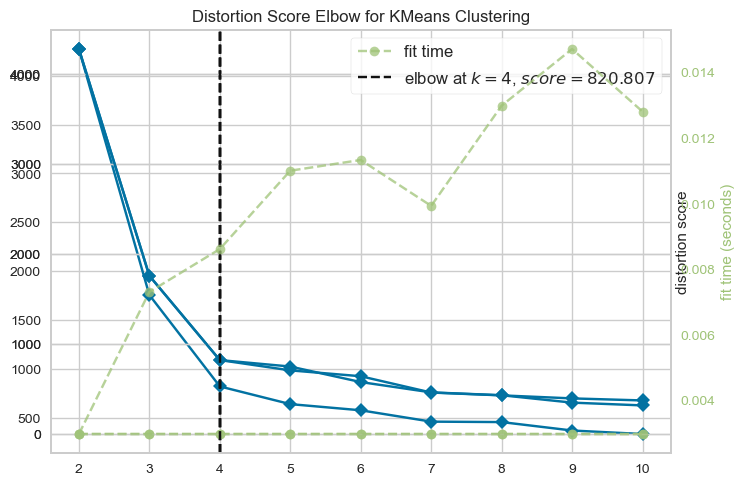

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [49]:
elbow_visualizer.fig
elbow_visualizer.show()

In [50]:
silhouette_score(features1,cluster.labels_)

0.6542051257543084

In [57]:
## KMeans 
kmeans = KMeans(n_clusters=3,random_state=50)
cluster = kmeans.fit(features1)
silhouette_score(features1,cluster.labels_)

0.8046268444611562